ARTI308 - Machine Learning

# Lab 3 Assignment: Exploratory Data Analysis (EDA)

**Dataset:** Flower Shop Sales (`flowershopdata.csv`)

Each row is one sales record of a flower: the flower name, its description, care needs, blooming season, sale status, sale date, and the client's name and phone number.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

## 2. Load Data

In [2]:
df = pd.read_csv("../Lab_03/data/flowershopdata.csv")
df.head()

,Name,Description,Needs,Season,Status,Date,Client Name,Client phone number,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,PERIWINKLE,"Perfect as a grown cover, the flowers resemble...",Needs droughty.,Blooms in mid-spring to mid-fall.,Sold,"Apr. 14, 2016",Erin Moon,(874) 453-1738,NaN,NaN,NaN
1,BELLFLOWER,"Known for their resemblance to bells, these fl...",Needs well-drained soil.,Blooms in early�summer�to�early�fall.,Sold,"Apr. 17, 2016",Gracie Chung,(521) 746-8022,NaN,NaN,NaN
2,LILY,A highly recognized flower which has bright co...,Needs well-drained soil.,Blooms in spring to early fall.,Sold,"Apr. 19, 2016",Josephine Pham,(867) 833-8676,NaN,NaN,NaN
3,TULIP,"Great as a cut flower, they come in every colo...",Needs well-drained soil,Blooms in spring,Sold,"Apr. 23, 2016",Alex Edwards,(488) 820-6420,NaN,NaN,NaN
4,LILY,A highly recognized flower which has bright co...,Needs well-drained soil.,Blooms in spring to early fall.,Sold,"Apr. 24, 2016",Izaiah Levine,(631) 972-2819,NaN,NaN,NaN


Most of the dataset's columns contain text vales, also some missing values are observed.

## 3. Data Types of Columns

In [3]:
df.dtypes

Name                       str
Description                str
Needs                      str
Season                     str
Status                     str
Date                       str
Client Name                str
Client phone number        str
Unnamed: 8             float64
Unnamed: 9             float64
Unnamed: 10            float64
dtype: object

Depending on the result, most of columns tayps are str, with 3 unnamed coulmns of type float

## 4. Data Cleaning

### 4.1 Remove empty columns

In [4]:
# Columns with no header and no values (Unnamed: 8, 9, 10)
print(df.filter(like="Unnamed").isna().all())

df = df.drop(columns=df.filter(like="Unnamed").columns)
df.columns.tolist()

Unnamed: 8     True
Unnamed: 9     True
Unnamed: 10    True
dtype: bool


['Name',
 'Description',
 'Needs',
 'Season',
 'Status',
 'Date',
 'Client Name',
 'Client phone number']

Dropping unnamed columns with no values

### 4.2 Fix the Date column

In [5]:
# Dates look like 'Apr. 14, 2016', so we remove the dots and give pandas the exact format
df["Date"] = pd.to_datetime(df["Date"].str.replace(".", "", regex=False), format="%b %d, %Y")
df.dtypes

Name                              str
Description                       str
Needs                             str
Season                            str
Status                            str
Date                   datetime64[us]
Client Name                       str
Client phone number               str
dtype: object

Convert the **Date** column to datetime type 

### 4.3 Fix text problems

In [6]:
# Broken characters (encoding problem) appear in some Season and Description values
print(df["Season"].str.contains("\ufffd").sum(), "Season values have broken characters")
for col in ["Season", "Description"]:
    df[col] = df[col].str.replace("\ufffd", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()

# 'Needs' has the same text written two ways (with and without a final dot)
print(df["Needs"].unique())
df["Needs"] = df["Needs"].str.rstrip(".")
print(df["Needs"].unique())

54 Season values have broken characters
<ArrowStringArray>
['Needs droughty.', 'Needs well-drained soil.', 'Needs well-drained soil']
Length: 3, dtype: str
<ArrowStringArray>
['Needs droughty', 'Needs well-drained soil']
Length: 2, dtype: str


**Observation:**
Some Season and Description values contained broken characters (encoding problem) instead of spaces, so we replaced them with normal spaces. The Needs column had the same text written two ways (with and without a final dot), so we removed the dot to make it consistent.

## 5. Check Missing Values

In [7]:
print(df.isna().sum())

Name                   0
Description            0
Needs                  0
Season                 0
Status                 0
Date                   0
Client Name            0
Client phone number    0
dtype: int64


**Observation:** The result indicated that there is no presence for missing values in any column, which means no further missing values handling needed.

## 6. Check Duplicate Rows

In [8]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(["Date", "Client Name"]).head(10)

Duplicate rows: 57


,Name,Description,Needs,Season,Status,Date,Client Name,Client phone number
31,BLOODROOT,Named for its red colored sap that flows from ...,Needs well-drained soil,Blooms in early spring.,Sold,2016-02-09,Charles Luna,(724) 676-8288
62,BLOODROOT,Named for its red colored sap that flows from ...,Needs well-drained soil,Blooms in early spring.,Sold,2016-02-09,Charles Luna,(724) 676-8288
26,LILY,A highly recognized flower which has bright co...,Needs well-drained soil,Blooms in spring to early fall.,Sold,2016-02-11,Charles Luna,(724) 676-8288
57,LILY,A highly recognized flower which has bright co...,Needs well-drained soil,Blooms in spring to early fall.,Sold,2016-02-11,Charles Luna,(724) 676-8288
27,BELLFLOWER,"Known for their resemblance to bells, these fl...",Needs well-drained soil,Blooms in early summer to early fall.,Sold,2016-02-15,Alex Edwards,(488) 820-6420
58,BELLFLOWER,"Known for their resemblance to bells, these fl...",Needs well-drained soil,Blooms in early summer to early fall.,Sold,2016-02-15,Alex Edwards,(488) 820-6420
28,ROSE,Over 100 species of rose exist along with almo...,Needs well-drained soil,Blooms in late spring to early fall.,Sold,2016-02-22,Gracie Chung,(521) 746-8022
59,ROSE,Over 100 species of rose exist along with almo...,Needs well-drained soil,Blooms in late spring to early fall.,Sold,2016-02-22,Gracie Chung,(521) 746-8022
29,ROSE,Over 100 species of rose exist along with almo...,Needs well-drained soil,Blooms in late spring to early fall.,Sold,2016-02-23,Karma Hampton,(320) 489-9174
60,ROSE,Over 100 species of rose exist along with almo...,Needs well-drained soil,Blooms in late spring to early fall.,Sold,2016-02-23,Karma Hampton,(320) 489-9174


In [9]:
# The same record is repeated several times (exact duplicates), so we keep only one copy of each
print("Rows before:", len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after: ", len(df))

Rows before: 106
Rows after:  49


**Observation:** There are 57 exact duplicate rows (the same record repeated up to 5 times), so we removed them and kept 49 unique rows.

## 7. Number of Rows and Columns

In [10]:
print("Shape (rows, columns):", df.shape)
print("number of rows:", df.shape[0])
print("number of columns:", df.shape[1])

Shape (rows, columns): (49, 8)
number of rows: 49
number of columns: 8


**Observation:** The dataset has 49 rows and 8 columns after removing the 3 empty columns and the duplicate rows. Each row is one flower sale (name, description, care needs, season, status, date, client name and client phone number), and this size is small enough to explore easily.

## 8. Descriptive Summary Statistics

In [11]:
df.describe(include='all')

,Name,Description,Needs,Season,Status,Date,Client Name,Client phone number
count,49,49,49,49,49,49,49,49
unique,8,8,2,8,1,NaN,22,22
top,ROSE,Over 100 species of rose exist along with almo...,Needs well-drained soil,Blooms in late spring to early fall.,Sold,NaN,Izaiah Levine,(631) 972-2819
freq,16,16,46,16,49,NaN,4,4
mean,NaN,NaN,NaN,NaN,NaN,2016-06-18 03:55:06.122449,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,2016-01-17 00:00:00,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,2016-04-03 00:00:00,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,2016-05-29 00:00:00,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,2016-09-10 00:00:00,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,2016-12-21 00:00:00,NaN,NaN


**Observation:** All 8 columns have 49 values, so there is no missing data. The dataset has 8 different flowers (ROSE is the most frequent with 16 sales), 22 different clients, and sales dates from January to December 2016. The Status column has only one value ("Sold"), so it gives no useful information, and Needs is almost always "well-drained soil" (46 of 49 rows).

## 9. Univariate Analysis

### 9.1 Sales by Flower

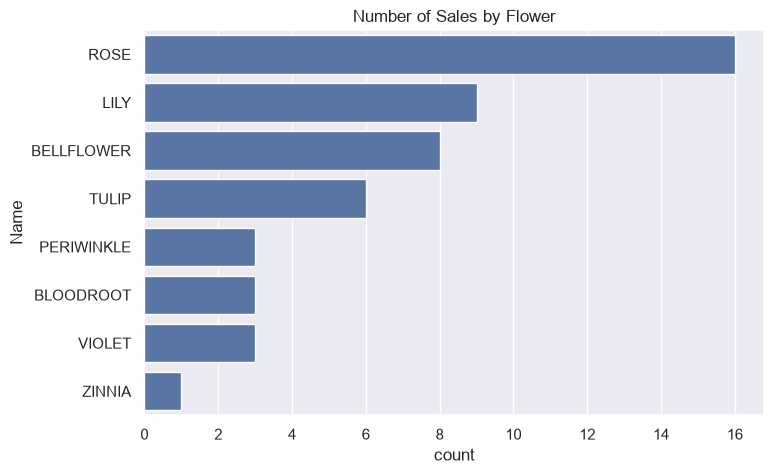

Name
ROSE          16
LILY           9
BELLFLOWER     8
TULIP          6
PERIWINKLE     3
BLOODROOT      3
VIOLET         3
ZINNIA         1
Name: count, dtype: int64

In [12]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, y="Name", order=df["Name"].value_counts().index)
plt.title("Number of Sales by Flower")
plt.show()

df["Name"].value_counts()

**Observation:** Rose is the best-selling flower with 16 sales, about one third of all sales, followed by Lily (9) and Bellflower (8). Zinnia sells the least (only 1 sale), so the sales are not evenly distributed between flowers.

### 9.2 Sales by Client

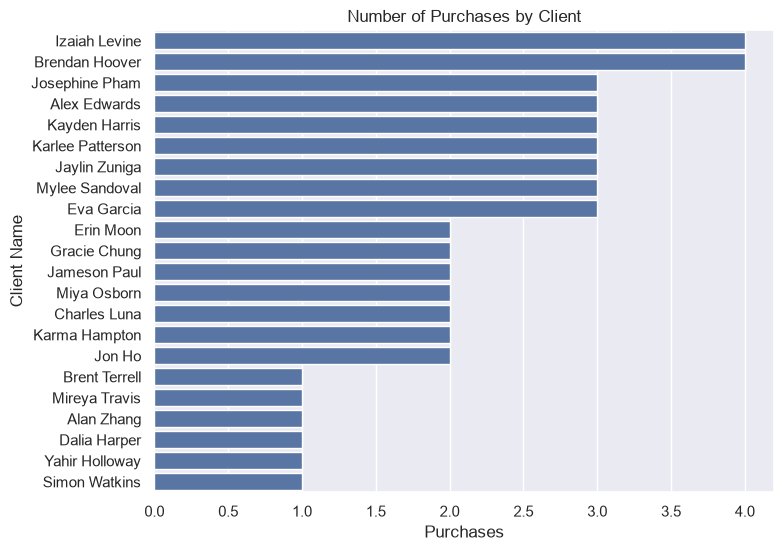

Client Name
Izaiah Levine     4
Brendan Hoover    4
Josephine Pham    3
Alex Edwards      3
Kayden Harris     3
Name: count, dtype: int64

In [13]:
client_counts = df["Client Name"].value_counts()

plt.figure(figsize=(8,6))
sns.barplot(x=client_counts.values, y=client_counts.index)
plt.title("Number of Purchases by Client")
plt.xlabel("Purchases")
plt.show()

client_counts.head(5)

**Observation:** Izaiah Levine and Brendan Hoover are the top clients with 4 purchases each. Most clients (16 of 22) bought more than once, and 6 clients bought only once, which shows that many clients come back.

### 9.3 Sales by Day of the Week

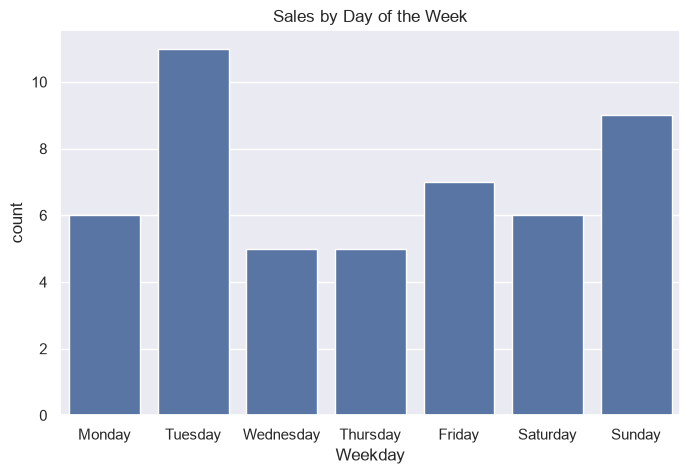

In [14]:
df["Weekday"] = df["Date"].dt.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Weekday", order=order)
plt.title("Sales by Day of the Week")
plt.show()

**Observation:** Tuesday has the most sales (11), followed by Sunday (9) and Friday (7), while Wednesday and Thursday have the fewest (5 each). Sales are not equal across the week, and some days are clearly busier than others.

### 9.4 Status and Care Needs

In [15]:
print(df["Status"].value_counts(), "\n")
print(df["Needs"].value_counts())

Status
Sold    49
Name: count, dtype: int64 

Needs
Needs well-drained soil    46
Needs droughty              3
Name: count, dtype: int64


**Observation:** All 49 records have the status "Sold", so this column has only one value and gives no useful information for comparing records. Most flowers need well-drained soil (46 records), and only 3 need "droughty" conditions, so this column is also very unbalanced.

## 10. Bivariate Analysis

### 10.1 Flower vs Blooming Season

In [16]:
df.groupby(["Name", "Season"]).size()

Name        Season                               
BELLFLOWER  Blooms in early summer to early fall.     8
BLOODROOT   Blooms in early spring.                   3
LILY        Blooms in spring to early fall.           9
PERIWINKLE  Blooms in mid-spring to mid-fall.         3
ROSE        Blooms in late spring to early fall.     16
TULIP       Blooms in spring                          6
VIOLET      Blooms in early spring to early fall.     3
ZINNIA      Blooms in mid-summer to mid-fall.         1
dtype: int64

**Observation:** Each flower has exactly one blooming season, so Name and Season carry the same information (the season is fixed for each flower). For example, Rose (16 sales) blooms from late spring to early fall, while Zinnia (1 sale) blooms from mid-summer to mid-fall.

### 10.2 Flower vs Month of Sale

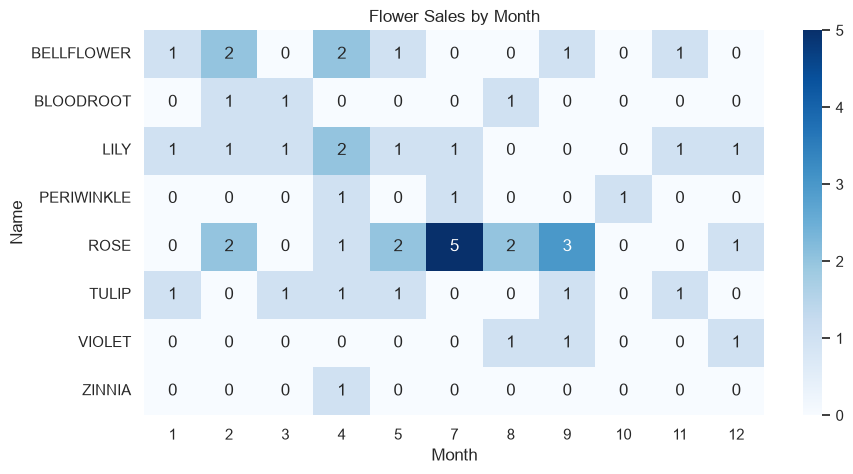

In [17]:
df["Month"] = df["Date"].dt.month

flower_month = pd.crosstab(df["Name"], df["Month"])

plt.figure(figsize=(10,5))
sns.heatmap(flower_month, annot=True, fmt="d", cmap="Blues")
plt.title("Flower Sales by Month")
plt.show()

**Observation:** Rose sells most in July (5 sales) and also sells in August, September and February/May, while April has sales of many different flowers (Bellflower, Lily, Periwinkle, Rose, Tulip and Zinnia). Zinnia was sold only once, in April, and no sales are recorded in June at all, so sales depend on the month and differ from flower to flower.

### 10.3 Top Clients and the Flowers They Buy

In [18]:
top_clients = df["Client Name"].value_counts().head(5).index
pd.crosstab(df[df["Client Name"].isin(top_clients)]["Client Name"],
            df[df["Client Name"].isin(top_clients)]["Name"])

Name,BELLFLOWER,BLOODROOT,LILY,ROSE,TULIP,VIOLET
Client Name,,,,,,
Alex Edwards,1,0,0,1,1,0
Brendan Hoover,0,0,0,2,2,0
Izaiah Levine,0,0,1,2,1,0
Josephine Pham,0,1,1,1,0,0
Kayden Harris,1,1,0,0,0,1


**Observation:** Each of the top clients bought 2 or 3 different flowers, and Rose and Tulip appear most often (for example Brendan Hoover bought Rose and Tulip twice each). Since each client has only 3 or 4 purchases, the numbers are small, so we cannot conclude strong flower preferences.

## 11. Correlation

This dataset has **no numeric columns** (no price, quantity, or amount), so a correlation matrix cannot be computed. The flower-by-month heatmap in section 10.2 is used as the closest alternative to show relationships between categorical variables.

## 12. Time-Based Analysis

### 12.1 Monthly Sales

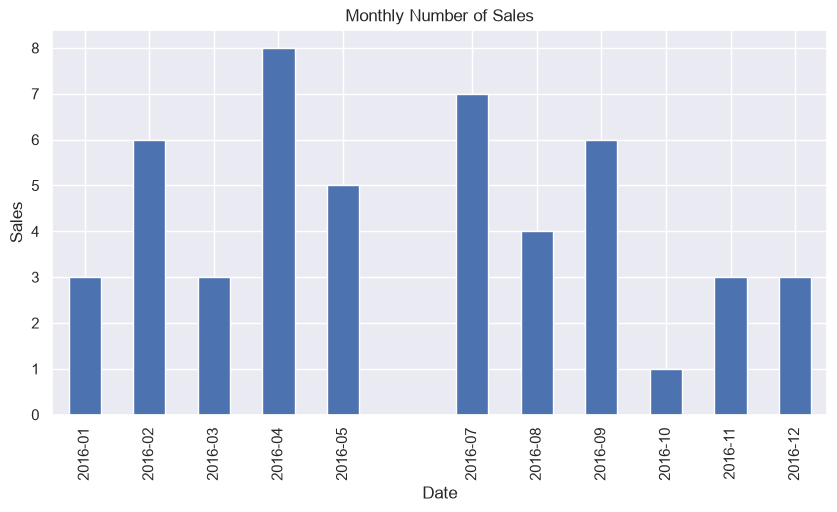

Date
2016-01    3
2016-02    6
2016-03    3
2016-04    8
2016-05    5
2016-07    7
2016-08    4
2016-09    6
2016-10    1
2016-11    3
2016-12    3
Freq: M, dtype: int64

In [19]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M")).size()

plt.figure(figsize=(10,5))
monthly_sales.plot(kind="bar")
plt.title("Monthly Number of Sales")
plt.ylabel("Sales")
plt.show()

monthly_sales

**Observation:** April has the highest number of sales (8), followed by July (7), while October has the lowest (1) and there are no sales in June. Sales go up and down during the year with no steady trend, and the end of the year (October to December) is weaker than the first half.

### 12.2 Sales Over Time

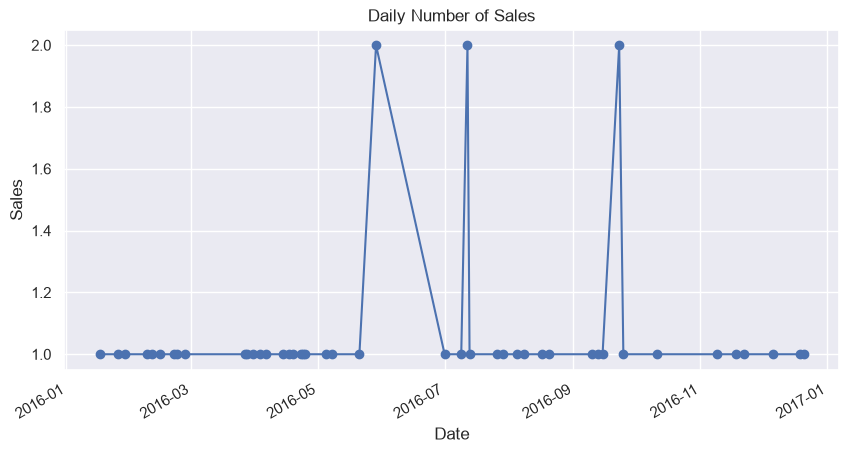

First sale: 2016-01-17
Last sale: 2016-12-21


In [20]:
daily_sales = df.groupby("Date").size()

plt.figure(figsize=(10,5))
daily_sales.plot(marker="o")
plt.title("Daily Number of Sales")
plt.ylabel("Sales")
plt.show()

print("First sale:", df["Date"].min().date())
print("Last sale:", df["Date"].max().date())

**Observation:** Almost every sales day has only 1 sale (43 of 46 days) and the maximum is 2 sales in a single day, so there are no big daily peaks. The chart only shows days with sales, so the line joins points across gaps in time, such as June where there are no sales.

## 13. Summary

This dataset contains 49 unique records of flower sales in 2016 and 8 columns (flower name, description, care needs, blooming season, status, date, client name and client phone number). During cleaning we removed 3 empty columns, converted the Date column to a date type, fixed broken characters in the Season and Description columns and the inconsistent text in the Needs column, and removed 57 exact duplicate rows (the original file had 106 rows). There are no missing values.

The main patterns we found are:
- Rose is the best-selling flower (16 sales, about one third of all sales), followed by Lily and Bellflower, while Zinnia sells the least (1 sale).
- There are 22 clients, and most of them (16) bought more than once, with at most 4 purchases per client.
- Sales are highest on Tuesday and change between months: April and July are the busiest, there are no sales in June, and October is the lowest.
- Almost every sales day has only one sale, so there are no big daily peaks.
- Status has only one value ("Sold") and Needs is almost always "well-drained soil", so these columns give little information.
- Each flower has exactly one blooming season, so Name and Season carry the same information.
- The dataset has no numeric columns, so a correlation matrix could not be computed.